In [1]:
import os
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class SimpleCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.fc1 = nn.Linear(64 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

    def predict_proba(self, x):
        return F.softmax(self.forward(x), dim=1)

c:\Users\user\Desktop\fruit_detecte\mp\.venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


WARNING imgsz=[2000] must be multiple of max stride 32, updating to [2016]
Найдено яблок: 29, из них гнилых: 18


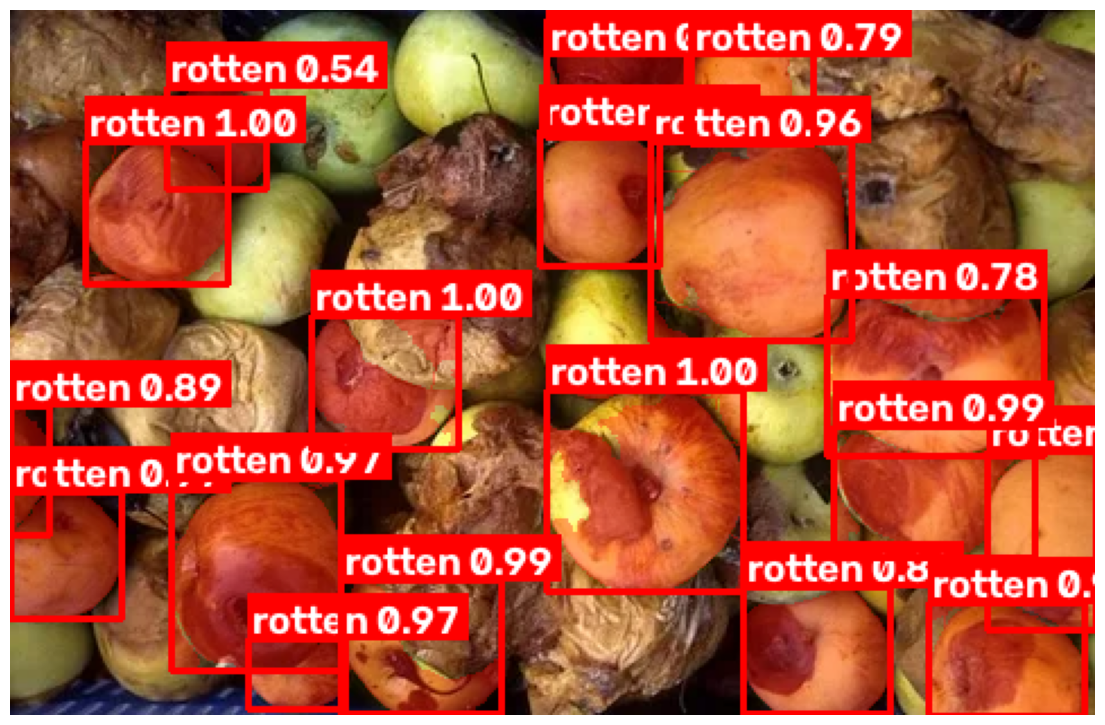

In [3]:
import cv2
import numpy as np
import torch
import torch.nn.functional as F
import torchvision.transforms as T
from PIL import Image
from ultralytics import YOLOE
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ==================== 1. ДЕТЕКТОР (YOLOE) ====================
names = ["apple"]   # что ищет YOLOE; замени, если у тебя другие текстовые классы
detector = YOLOE("../models/yoloe-26m-seg.pt")
detector.set_classes(names, detector.get_text_pe(names))

# ==================== 2. КЛАССИФИКАТОР (CNN) ====================
checkpoint = torch.load("../models/fruit_cnn.pt", map_location=device)
class_names = checkpoint["class_names"]          # ['fresh', 'rotten']
IMG_SIZE = checkpoint["img_size"]
ROTTEN_IDX = class_names.index("rotten")         # номер класса "гнилой"

classifier = SimpleCNN(num_classes=len(class_names)).to(device)
classifier.load_state_dict(checkpoint["model_state_dict"])
classifier.eval()   # режим предсказания

# Те же преобразования, что при обучении, но БЕЗ аугментаций
infer_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


# ==================== 3. ПАЙПЛАЙН ====================
def find_rotten(image_path, det_conf=0.05, det_imgsz=2000,
                rotten_thr=0.5, pad=0, draw_masks=True):
    """
    Возвращает:
      annotated — исходная картинка (BGR) с выделенными гнилыми яблоками
      rotten    — список словарей {box, rotten_prob} по гнилым яблокам
    """
    # --- 3.1 детекция ---
    result = detector.predict(image_path, conf=det_conf, imgsz=det_imgsz, verbose=False)[0]
    orig = result.orig_img.copy()        # исходная картинка в BGR (формат OpenCV)
    h, w = orig.shape[:2]

    if result.boxes is None or len(result.boxes) == 0:
        print("Яблоки не найдены")
        return orig, []

    boxes = result.boxes.xyxy.cpu().numpy().astype(int)   # [N, 4]: x1, y1, x2, y2

    # --- 3.2 вырезаем кусочки ---
    crops, kept = [], []
    for i, (x1, y1, x2, y2) in enumerate(boxes):
        x1, y1 = max(0, x1 - pad), max(0, y1 - pad)       # pad — запас вокруг рамки,
        x2, y2 = min(w, x2 + pad), min(h, y2 + pad)       # не выходим за границы картинки
        if x2 - x1 < 2 or y2 - y1 < 2:
            continue

        crop = orig[y1:y2, x1:x2]
        crop_pil = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))  # BGR -> RGB -> PIL
        crops.append(infer_tf(crop_pil))                  # -> тензор [3, IMG_SIZE, IMG_SIZE]
        kept.append((i, (x1, y1, x2, y2)))

    if not crops:
        return orig, []

    # --- 3.3 классификация всех кусочков одним батчем ---
    batch = torch.stack(crops).to(device)                 # [N, 3, IMG_SIZE, IMG_SIZE]
    with torch.no_grad():
        probs = F.softmax(classifier(batch), dim=1)[:, ROTTEN_IDX].cpu().numpy()

    rotten = [
        {"idx": i, "box": box, "rotten_prob": float(p)}
        for (i, box), p in zip(kept, probs) if p >= rotten_thr
    ]

    # --- 3.4 рисуем на исходной картинке ---
    annotated = orig.copy()

    # полупрозрачная красная заливка по маске сегментации
    if draw_masks and result.masks is not None and rotten:
        overlay = annotated.copy()
        polygons = result.masks.xy                        # контуры масок в координатах исходной картинки
        for r in rotten:
            poly = polygons[r["idx"]]
            if len(poly) > 0:
                cv2.fillPoly(overlay, [poly.astype(np.int32)], (0, 0, 255))
        annotated = cv2.addWeighted(overlay, 0.35, annotated, 0.65, 0)

    # рамки и подписи
    font_scale = max(0.6, w / 1500)
    thickness = max(2, int(w / 600))
    for r in rotten:
        x1, y1, x2, y2 = r["box"]
        cv2.rectangle(annotated, (x1, y1), (x2, y2), (0, 0, 255), thickness)

        label = f"rotten {r['rotten_prob']:.2f}"
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness)
        ty = max(th + 4, y1)
        cv2.rectangle(annotated, (x1, ty - th - 4), (x1 + tw + 4, ty), (0, 0, 255), -1)
        cv2.putText(annotated, label, (x1 + 2, ty - 2),
                    cv2.FONT_HERSHEY_SIMPLEX, font_scale, (255, 255, 255), thickness)

    print(f"Найдено яблок: {len(kept)}, из них гнилых: {len(rotten)}")
    return annotated, rotten


# ==================== 4. ЗАПУСК ====================
annotated, rotten = find_rotten("../used_data/image3.png")

cv2.imwrite("result.png", annotated)                      # сохранить результат

plt.figure(figsize=(14, 10))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))    # matplotlib ждёт RGB
plt.axis("off")
plt.show()